# B05 — Cross-currency swaps y divisa de la deuda

**Objetivos:** curva SOFR, basis de divisa y forwards EURUSD; valorar un cross-currency swap fijo-fijo; coste
sintético de deuda en USD; elegir la proporción de deuda en USD que protege el ratio deuda neta/EBITDA;
exposición del CCS por el intercambio de nominal.

**Fuentes:** Myint cap. 20–22 y 31; Hull cap. 7 y 33; Schofield & Bowler cap. 2. Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market, REF_DATE
from derivlab.curves import build_curves, discount_t
from derivlab.scenarios import HullWhite
from derivlab.fx import (build_sofr, basis_adjusted, fx_forward, par_rate, annuity, ccs_fair_usd_rate,
                         ccs_value_eur, ccs_value_paths, simulate_eurusd, leverage_paths, leverage_at_risk,
                         EURUSD_SPOT, XCCY_BASIS, SOFR_QUOTES)
from derivlab.xva import swap_value_paths, exposure_profile, xva, to_running_bp

m = sample_market()
estr, eur = build_curves(m)
sofr = build_sofr(REF_DATE)
eur_x = basis_adjusted(estr, XCCY_BASIS)       # EUR flows in a USD-collateralised trade
S0 = EURUSD_SPOT

## 1. Forwards EURUSD y basis

Paridad cubierta: $F(T) = S_0 \cdot P_{EUR}^{x}(T) / P_{USD}(T)$, con $P^x_{EUR}$ la curva €STR desplazada por el
basis (€STR − 10 pb frente a SOFR). Como los tipos USD están por encima de los EUR, el EUR cotiza con prima a plazo.

In [2]:
fx = pd.DataFrame({"T": [1, 2, 3, 5, 7, 10]})
fx["eur_par"] = [par_rate(eur_x, t) for t in fx["T"]]
fx["usd_par"] = [par_rate(sofr, t) for t in fx["T"]]
fx["forward"] = [fx_forward(S0, eur_x, sofr, t) for t in fx["T"]]
fx["forward_points"] = (fx.forward - S0) * 1e4
fx["no_basis_forward"] = [fx_forward(S0, estr, sofr, t) for t in fx["T"]]
print(fx.to_string(index=False, formatters={"eur_par": "{:.3%}".format, "usd_par": "{:.3%}".format,
                                            "forward": "{:.4f}".format, "forward_points": "{:.0f}".format,
                                            "no_basis_forward": "{:.4f}".format}))
print(f"CASE EURUSD spot {S0:.4f}; 5y forward {fx.forward.iloc[3]:.4f} ({fx.forward_points.iloc[3]:.0f} pips)")

 T eur_par usd_par forward forward_points no_basis_forward
 1  1.801%  3.449%  1.1788            188           1.1776
 2  1.884%  3.377%  1.1942            342           1.1918
 3  1.983%  3.387%  1.2085            485           1.2049
 5  2.158%  3.478%  1.2367            767           1.2305
 7  2.298%  3.579%  1.2654           1054           1.2566
10  2.454%  3.710%  1.3108           1508           1.2978
CASE EURUSD spot 1.1600; 5y forward 1.2367 (767 pips)


## 2. Un CCS fijo-fijo a 5 años: deuda en USD sintética

La empresa emite un bono a 5 años en EUR (€STR par + 1,10 % de diferencial) y lo convierte a USD con un CCS:
entrega los euros recibidos, recibe dólares; cobra el cupón EUR y paga un fijo USD; al vencimiento se deshace el
intercambio. El fijo USD justo cumple $c_e A_e + P_e(T) - 1 = c_u A_u + P_u(T) - 1$.

In [3]:
CS_EUR, CS_USD = 0.0110, 0.0130
c_eur = par_rate(estr, 5) + CS_EUR
rows = []
for b in [0.0, -0.0010, -0.0025]:
    cu = ccs_fair_usd_rate(basis_adjusted(estr, b), sofr, 5, c_eur)
    rows.append({"basis_bp": b * 1e4, "synthetic_usd_fixed": cu})
syn = pd.DataFrame(rows)
direct = par_rate(sofr, 5) + CS_USD
syn["vs_direct_usd_issue_bp"] = (syn.synthetic_usd_fixed - direct) * 1e4
print(f"EUR bond coupon {c_eur:.3%}; direct USD bond {direct:.3%} (SOFR par + 1.30%)")
print(syn.to_string(index=False, formatters={"basis_bp": "{:.0f}".format, "synthetic_usd_fixed": "{:.3%}".format,
                                             "vs_direct_usd_issue_bp": "{:+.1f}".format}))
cu = syn.synthetic_usd_fixed.iloc[1]
print(f"CASE EUR bond {c_eur:.3%} swapped to USD costs {cu:.3%}; direct USD issue {direct:.3%}; "
      f"each -10 bp of basis adds about {(syn.synthetic_usd_fixed.iloc[1] - syn.synthetic_usd_fixed.iloc[0]) * 1e4:.1f} bp")

EUR bond coupon 3.360%; direct USD bond 4.778% (SOFR par + 1.30%)
basis_bp synthetic_usd_fixed vs_direct_usd_issue_bp
       0              4.619%                  -15.9
     -10              4.728%                   -4.9
     -25              4.893%                  +11.6
CASE EUR bond 3.360% swapped to USD costs 4.728%; direct USD issue 4.778%; each -10 bp of basis adds about 10.9 bp


Con basis negativo, quien convierte EUR en USD recibe la pata EUR a €STR menos el basis: le cuesta más. Al
revés, un emisor estadounidense que emite en USD y lo convierte a EUR se beneficia. El basis refleja la
demanda de financiación en dólares.

## 3. Caso: proteger el ratio deuda neta/EBITDA

**Grupo Industrial Ibérico** (ficticio) tiene un EBITDA de 2.000 M€, el 40 % generado en USD, y una deuda neta
de 6.800 M€, toda en EUR: un ratio de 3,4x. Su rating se revisaría por encima de 3,5x. Si el dólar se deprecia,
el EBITDA en euros cae y el ratio sube.

Siguiendo a Myint (cap. 22), el riesgo es el **leverage-at-risk**: el aumento del ratio en un año al percentil 95.
El EBITDA en USD se convierte al tipo medio del año; la deuda en USD, al tipo de cierre. Volatilidad EURUSD: 8 %.

In [4]:
EBITDA, USD_SHARE, NET_DEBT, TRIGGER = 2000.0, 0.40, 6800.0, 3.5
base = NET_DEBT / EBITDA
t_fx, paths = simulate_eurusd(S0, eur_x, sofr, 1.0, 12, 40000, vol=0.08, seed=5)
carry = par_rate(sofr, 5) - par_rate(eur_x, 5)
rows = []
for share in np.round(np.arange(0, 0.61, 0.05), 2):
    lev = leverage_paths(paths, EBITDA, USD_SHARE, NET_DEBT, share, S0)
    rows.append({"usd_debt_share": share, "LaR95": leverage_at_risk(lev, base), "p95_ratio": np.quantile(lev, 0.95),
                 "prob_above_trigger": (lev > TRIGGER).mean(), "carry_meur": carry * NET_DEBT * share})
lar = pd.DataFrame(rows)
print(lar.to_string(index=False, formatters={"usd_debt_share": "{:.0%}".format, "LaR95": "{:.3f}x".format,
                                             "p95_ratio": "{:.2f}x".format, "prob_above_trigger": "{:.2%}".format,
                                             "carry_meur": "{:.0f}".format}))
best = lar.loc[lar.LaR95.idxmin()]
print(f"CASE all-EUR debt: LaR {lar.LaR95.iloc[0]:.3f}x, P(ratio > 3.5x) {lar.prob_above_trigger.iloc[0]:.2%}")
print(f"CASE minimum-risk USD share {best.usd_debt_share:.0%}: LaR {best.LaR95:.3f}x, P(> 3.5x) {best.prob_above_trigger:.2%}, "
      f"carry {best.carry_meur:.0f} M EUR per year")
print(f"CASE naive 40% (= EBITDA share): LaR {lar[lar.usd_debt_share == 0.4].LaR95.iloc[0]:.3f}x, carry "
      f"{lar[lar.usd_debt_share == 0.4].carry_meur.iloc[0]:.0f} M EUR per year")

usd_debt_share  LaR95 p95_ratio prob_above_trigger carry_meur
            0% 0.119x     3.52x              8.86%          0
            5% 0.099x     3.50x              4.77%          4
           10% 0.080x     3.48x              1.92%          9
           15% 0.064x     3.46x              0.47%         13
           20% 0.055x     3.45x              0.11%         18
           25% 0.055x     3.46x              0.18%         22
           30% 0.064x     3.46x              0.71%         27
           35% 0.078x     3.48x              2.14%         31
           40% 0.095x     3.50x              4.33%         36
           45% 0.114x     3.51x              6.97%         40
           50% 0.132x     3.53x              9.78%         45
           55% 0.152x     3.55x             12.42%         49
           60% 0.172x     3.57x             14.90%         54
CASE all-EUR debt: LaR 0.119x, P(ratio > 3.5x) 8.86%
CASE minimum-risk USD share 20%: LaR 0.055x, P(> 3.5x) 0.11%, carry 18 M EUR pe

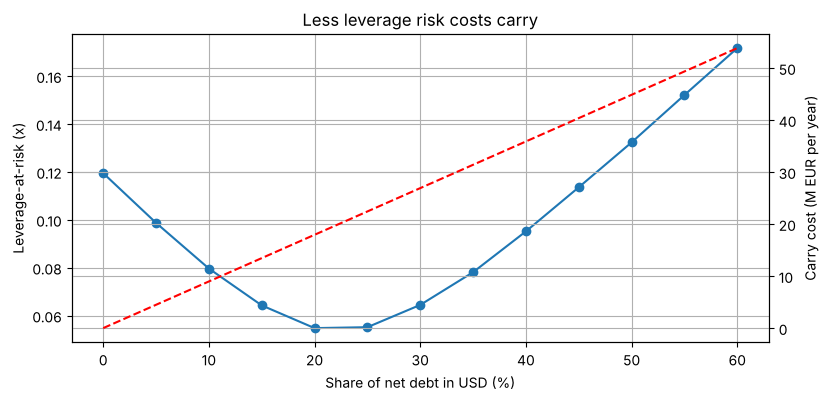

In [5]:
fig, ax1 = plt.subplots()
ax1.plot(lar.usd_debt_share * 100, lar.LaR95, "o-", label="LaR 95%")
ax1.set_xlabel("Share of net debt in USD (%)"); ax1.set_ylabel("Leverage-at-risk (x)")
ax2 = ax1.twinx(); ax2.plot(lar.usd_debt_share * 100, lar.carry_meur, "r--", label="carry cost (M EUR)")
ax2.set_ylabel("Carry cost (M EUR per year)")
ax1.set_title("Less leverage risk costs carry"); plt.show()

**Lectura.** La proporción que minimiza el riesgo no es la del EBITDA (40 %), sino alrededor de la mitad: el
EBITDA se convierte a tipo medio, que se mueve menos que el tipo de cierre con el que se convierte la deuda.
Cada punto de deuda en USD cuesta *carry*, porque los tipos USD son más altos, así que la decisión final es
cuánto *carry* paga la empresa por bajar la probabilidad de superar 3,5x.

## 4. El precio oculto: exposición del CCS

El intercambio de nominal al vencimiento hace que la exposición de un CCS dependa del tipo de cambio sobre todo
el nominal. Se compara con un swap de tipos del mismo nominal y plazo (Hull-White de B04).

CASE CCS on 1,360 M EUR: peak PFE 510 M EUR (37% of notional) vs IRS peak PFE 103 M EUR (8%)


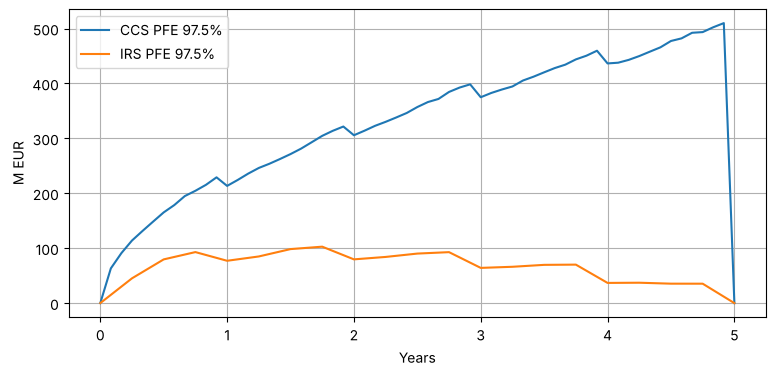

CASE CVA at 80 bp CDS: CCS 3.3 bp per year vs IRS 0.9 bp per year


In [6]:
N_CCS = NET_DEBT * best.usd_debt_share
c_e5 = par_rate(eur_x, 5)
c_u5 = ccs_fair_usd_rate(eur_x, sofr, 5, c_e5)
t5, fx5 = simulate_eurusd(S0, eur_x, sofr, 5.0, 60, 20000, vol=0.08, seed=8)
Vccs = ccs_value_paths(t5, fx5, eur_x, sofr, 5, N_CCS, S0, c_e5, c_u5, bank_receives_usd=True)
pfe_ccs = np.quantile(np.maximum(Vccs, 0), 0.975, axis=0)
ee_ccs = np.maximum(Vccs, 0).mean(axis=0)

hw = HullWhite(estr, eur, a=0.03, sigma=0.0085)
k5, A5 = hw.swap_rate(0.0, np.zeros(1), 5)
ti, Virs, Dirs = swap_value_paths(hw, N_CCS * 1e6, float(k5[0]), 5, n_paths=6000, seed=4)
prof_irs = exposure_profile(ti, Virs, Dirs)
print(f"CASE CCS on {N_CCS:,.0f} M EUR: peak PFE {pfe_ccs.max():,.0f} M EUR ({pfe_ccs.max() / N_CCS:.0%} of notional) "
      f"vs IRS peak PFE {prof_irs.PFE.max() / 1e6:,.0f} M EUR ({prof_irs.PFE.max() / 1e6 / N_CCS:.0%})")
plt.plot(t5, pfe_ccs, label="CCS PFE 97.5%"); plt.plot(ti, prof_irs.PFE / 1e6, label="IRS PFE 97.5%")
plt.xlabel("Years"); plt.ylabel("M EUR"); plt.legend(); plt.show()

prof_ccs = pd.DataFrame({"t": t5, "EE_disc": ee_ccs * 1e6 * discount_t(estr, t5), "NEE_disc": 0.0 * t5})
cva_ccs = xva(prof_ccs, cpty_spread=0.0080)["CVA"]
cva_irs = xva(prof_irs, cpty_spread=0.0080)["CVA"]
ann_e = annuity(eur_x, 5)
print(f"CASE CVA at 80 bp CDS: CCS {to_running_bp(cva_ccs, N_CCS * 1e6, ann_e):.1f} bp per year vs IRS "
      f"{to_running_bp(cva_irs, N_CCS * 1e6, ann_e):.1f} bp per year")

## 5. Comprobaciones

In [7]:
assert abs(ccs_value_eur(S0, eur_x, sofr, 5, 100.0, c_e5, c_u5)) < 1e-9
assert abs(Vccs[:, 0].mean()) < 0.01 * N_CCS                      # fair at inception (up to MC noise)
assert (fx.forward > S0).all()
assert syn.synthetic_usd_fixed.is_monotonic_increasing             # more negative basis, dearer USD
assert 0.10 <= best.usd_debt_share <= 0.35
assert pfe_ccs.max() > 3 * prof_irs.PFE.max() / 1e6
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** Calcula el forward EURUSD a 3 años sin basis y con −25 pb. ¿Cuántos *pips* cambia?
2. **Intermedio.** Si la volatilidad del EURUSD sube al 12 %, ¿cambia la proporción óptima de deuda en USD? ¿Y el LaR con toda la deuda en EUR?
3. **Avanzado.** Diseña la cobertura con un *net investment hedge*: la empresa contrata el CCS y lo designa como cobertura de su filial en USD. ¿Qué parte del ratio protege y qué parte del riesgo de flujos queda abierta?

## Soluciones

In [8]:
f0 = fx_forward(S0, estr, sofr, 3); f25 = fx_forward(S0, basis_adjusted(estr, -0.0025), sofr, 3)
print(f"3y forward no basis {f0:.4f}, basis -25 bp {f25:.4f}: {(f25 - f0) * 1e4:.0f} pips")

3y forward no basis 1.2049, basis -25 bp 1.2139: 91 pips


In [9]:
_, p12 = simulate_eurusd(S0, eur_x, sofr, 1.0, 12, 40000, vol=0.12, seed=5)
r12 = [leverage_at_risk(leverage_paths(p12, EBITDA, USD_SHARE, NET_DEBT, s, S0), base) for s in lar.usd_debt_share]
print(f"Vol 12%: LaR all-EUR {r12[0]:.3f}x; minimum at {lar.usd_debt_share[int(np.argmin(r12))]:.0%} USD")
print("The optimal share does not depend on the volatility level, only on the average-versus-closing effect.")

Vol 12%: LaR all-EUR 0.172x; minimum at 20% USD
The optimal share does not depend on the volatility level, only on the average-versus-closing effect.


In [10]:
print("A net investment hedge sends the FX gains and losses of the USD debt (or of the CCS) to equity, where they\n"
      "offset the translation of the USD subsidiary's net assets: it protects book equity and keeps P&L clean.\n"
      "It does not protect the translation of USD EBITDA, a flow converted at average rates. Protecting book value\n"
      "(Myint ch. 21) and protecting leverage (ch. 22) call for different amounts of USD debt.")

A net investment hedge sends the FX gains and losses of the USD debt (or of the CCS) to equity, where they
offset the translation of the USD subsidiary's net assets: it protects book equity and keeps P&L clean.
It does not protect the translation of USD EBITDA, a flow converted at average rates. Protecting book value
(Myint ch. 21) and protecting leverage (ch. 22) call for different amounts of USD debt.
